In [13]:
%pip install scikit-learn pillow numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
documents=[
    "The sun is shining today . ",
    "The weather is good, the sun is great . ",
    "A sunny day is a wonderful day."
]
print("---Raw Text Documents--- ")
for i, doc in enumerate(documents):
    print(f"Doc {i+1}: {doc}")

---Raw Text Documents--- 
Doc 1: The sun is shining today . 
Doc 2: The weather is good, the sun is great . 
Doc 3: A sunny day is a wonderful day.


In [4]:
# 2. Apply Feature Engineering: CountVectorizer (Bag-of-Words)
#    CountVectorizer performs tokenization AND vocabulary building in one step.
vectorizer = CountVectorizer()

# fit_transform learns the vocabulary and converts the documents into feature vectors
X_text = vectorizer.fit_transform(documents)

# 3. Analyze the Results
feature_names = vectorizer.get_feature_names_out()
text_matrix = X_text.toarray()

print("--- Bag-of-Words (BoW) Transformation ---")
print(f"Vocabulary (Features): {feature_names}")
print(f"Shape of Feature Matrix: {text_matrix.shape}   (documents x unique terms)")
print(text_matrix)

--- Bag-of-Words (BoW) Transformation ---
Vocabulary (Features): ['day' 'good' 'great' 'is' 'shining' 'sun' 'sunny' 'the' 'today' 'weather'
 'wonderful']
Shape of Feature Matrix: (3, 11)   (documents x unique terms)
[[0 0 0 1 1 1 0 1 1 0 0]
 [0 1 1 2 0 1 0 2 0 1 0]
 [2 0 0 1 0 0 1 0 0 0 1]]


In [5]:
# A DataFrame view, purely so the matrix is readable
df_text = pd.DataFrame(text_matrix, columns=feature_names,
                       index=[f"Doc {i+1}" for i in range(len(documents))])

print("BoW Numerical Feature Matrix (Machine Understandable Format):\n")
display(df_text)


BoW Numerical Feature Matrix (Machine Understandable Format):



,day,good,great,is,shining,sun,sunny,the,today,weather,wonderful
Doc 1,0,0,0,1,1,1,0,1,1,0,0
Doc 2,0,1,1,2,0,1,0,2,0,1,0
Doc 3,2,0,0,1,0,0,1,0,0,0,1


In [6]:
print("Is 'a' in the vocabulary? ", 'a' in feature_names)
print("Is 'the' in the vocabulary?", 'the' in feature_names)
print()
print("Default token pattern :", vectorizer.token_pattern)
print("Lowercase enabled     :", vectorizer.lowercase)
print()
print("The token pattern requires 2+ word characters, which is why 'a' is dropped.")

Is 'a' in the vocabulary?  False
Is 'the' in the vocabulary? True

Default token pattern : (?u)\b\w\w+\b
Lowercase enabled     : True

The token pattern requires 2+ word characters, which is why 'a' is dropped.


In [7]:
# Sparsity: how much of this matrix is zero? This is the defining property of BoW.
total_cells = text_matrix.size   #total number of cells in the matrix (rows × columns). With 3 documents and 11 vocabulary terms, that's 3 × 11 = 33 cells.
zero_cells = (text_matrix == 0).sum()

print(f"Matrix cells : {total_cells}")
print(f"Zero cells   : {zero_cells}")
print(f"Sparsity     : {zero_cells / total_cells:.1%}")
print()
print("With a real corpus of 20,000 documents this figure exceeds 99%,")
print("which is why scikit-learn returns a SPARSE matrix, not a dense array.")
print("Type returned by fit_transform:", type(X_text))

Matrix cells : 33
Zero cells   : 18
Sparsity     : 54.5%

With a real corpus of 20,000 documents this figure exceeds 99%,
which is why scikit-learn returns a SPARSE matrix, not a dense array.
Type returned by fit_transform: <class 'scipy.sparse._csr.csr_matrix'>


In [9]:
import numpy as np
from PIL import Image
import os

# --- Configuration for image loading ------------------------------------
# Set to None to use a dummy image, or to a path string for your own image.
#   e.g. 'my_image.png'  or  'C:/Users/You/Pictures/photo.jpg'
image_file_path = "C:/Users/DELL/Downloads/New folder/123.jpg"

# 1. Load Image or Create a Dummy Image
original_image = None
if image_file_path and os.path.exists(image_file_path):
    try:
        original_image = Image.open(image_file_path)
        print(f"--- Loaded Image from File: {image_file_path} ---")
    except Exception as e:
        print(f"Error loading image from {image_file_path}: {e}")
        dummy = np.random.randint(0, 256, size=(100, 100, 3), dtype=np.uint8)
        original_image = Image.fromarray(dummy, 'RGB')
        print("--- Created Dummy Image (100x100 RGB) ---")
else:
    print("No valid image file path provided or file not found.")
    dummy = np.random.randint(0, 256, size=(100, 100, 3), dtype=np.uint8)
    original_image = Image.fromarray(dummy, 'RGB')
    print("--- Created Dummy Image (100x100 RGB) ---")

# Ensure a consistent 3-channel representation
original_image = original_image.convert('RGB')
original_image_array = np.array(original_image)

h, w, c = original_image_array.shape
print(f"Original Image Size (H, W, Channels): {original_image_array.shape}")
print(f"Total Features (Pixels) in RGB: {h * w * c}")

--- Loaded Image from File: C:/Users/DELL/Downloads/New folder/123.jpg ---
Original Image Size (H, W, Channels): (4032, 3024, 3)
Total Features (Pixels) in RGB: 36578304


In [10]:
# 2. Feature Engineering step 1: Grayscale Conversion ('L' mode = luminance)
grayscale_image = original_image.convert('L')
grayscale_array = np.array(grayscale_image)

print("--- Grayscale Conversion (Feature Reduction) ---")
print(f"Grayscale Image Size (H, W): {grayscale_array.shape}")
print(f"Total Features (Pixels) after Grayscale: {grayscale_array.size}")
print()
print(f"Reduction factor: {(h * w * c) / grayscale_array.size:.0f}x fewer features")

--- Grayscale Conversion (Feature Reduction) ---
Grayscale Image Size (H, W): (4032, 3024)
Total Features (Pixels) after Grayscale: 12192768

Reduction factor: 3x fewer features


In [11]:
# 3. Feature Engineering step 2: Pixel Flattening (2D matrix -> 1D vector)
flattened_features = grayscale_array.flatten()

print("--- Pixel Flattening (Vectorization) ---")
print(f"Flattened Feature Vector Shape: {flattened_features.shape}")
print()
print("First 10 Features (Pixel Values) in Machine Understandable Format:")
print(flattened_features[:10])
print()
print(f"Data Type of Final Features: {flattened_features.dtype}")

--- Pixel Flattening (Vectorization) ---
Flattened Feature Vector Shape: (12192768,)

First 10 Features (Pixel Values) in Machine Understandable Format:
[17 17 17 18 18 18 19 19 17 16]

Data Type of Final Features: uint8


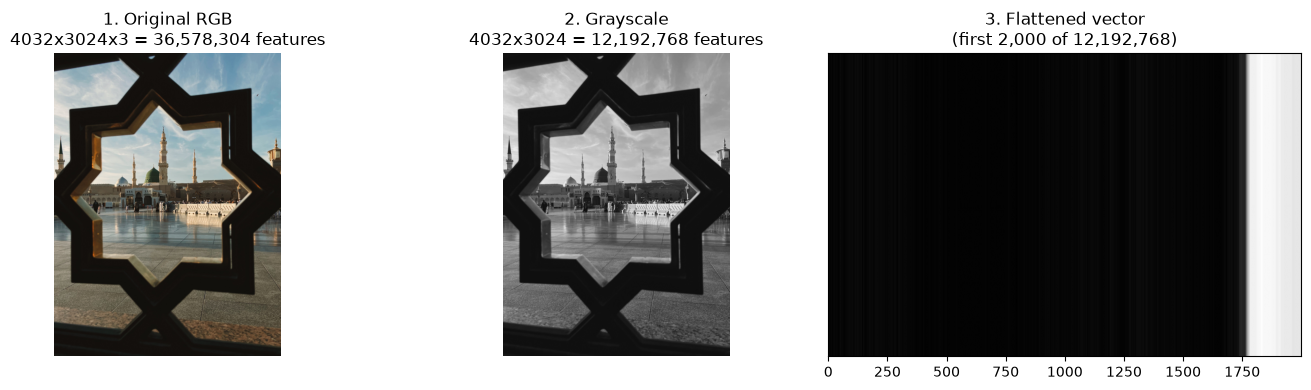

In [12]:
# Show all three stages side by side so the loss of information is visible.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(original_image)
axes[0].set_title(f"1. Original RGB\n{h}x{w}x{c} = {h*w*c:,} features")
axes[0].axis('off')

axes[1].imshow(grayscale_image, cmap='gray')
axes[1].set_title(f"2. Grayscale\n{h}x{w} = {h*w:,} features")
axes[1].axis('off')

# A 1-D vector drawn as a single row of pixels
axes[2].imshow(flattened_features[:2000].reshape(1, -1), cmap='gray', aspect='auto')
axes[2].set_title(f"3. Flattened vector\n(first 2,000 of {flattened_features.size:,})")
axes[2].set_yticks([])

plt.tight_layout()
plt.show()

In [13]:
# Exercise 1: Re-run BoW with unigrams + bigrams
vectorizer_bigram = CountVectorizer(ngram_range=(1, 2))
X_bigram = vectorizer_bigram.fit_transform(documents)
bigram_features = vectorizer_bigram.get_feature_names_out()

print(f"Original (unigram only) vocabulary size: {len(feature_names)}")
print(f"New (unigram + bigram) vocabulary size : {len(bigram_features)}")
print()
print("New vocabulary:", bigram_features)

Original (unigram only) vocabulary size: 11
New (unigram + bigram) vocabulary size : 24

New vocabulary: ['day' 'day is' 'good' 'good the' 'great' 'is' 'is good' 'is great'
 'is shining' 'is wonderful' 'shining' 'shining today' 'sun' 'sun is'
 'sunny' 'sunny day' 'the' 'the sun' 'the weather' 'today' 'weather'
 'weather is' 'wonderful' 'wonderful day']


In [14]:
# Exercise 2: Effect of a document with repeated words
documents_ex2 = documents + ["sun sun sun sun sun"]

vectorizer_ex2 = CountVectorizer()
X_ex2 = vectorizer_ex2.fit_transform(documents_ex2)
matrix_ex2 = X_ex2.toarray()

df_ex2 = pd.DataFrame(matrix_ex2, columns=vectorizer_ex2.get_feature_names_out(),
                       index=[f"Doc {i+1}" for i in range(len(documents_ex2))])
display(df_ex2)

,day,good,great,is,shining,sun,sunny,the,today,weather,wonderful
Doc 1,0,0,0,1,1,1,0,1,1,0,0
Doc 2,0,1,1,2,0,1,0,2,0,1,0
Doc 3,2,0,0,1,0,0,1,0,0,0,1
Doc 4,0,0,0,0,0,5,0,0,0,0,0


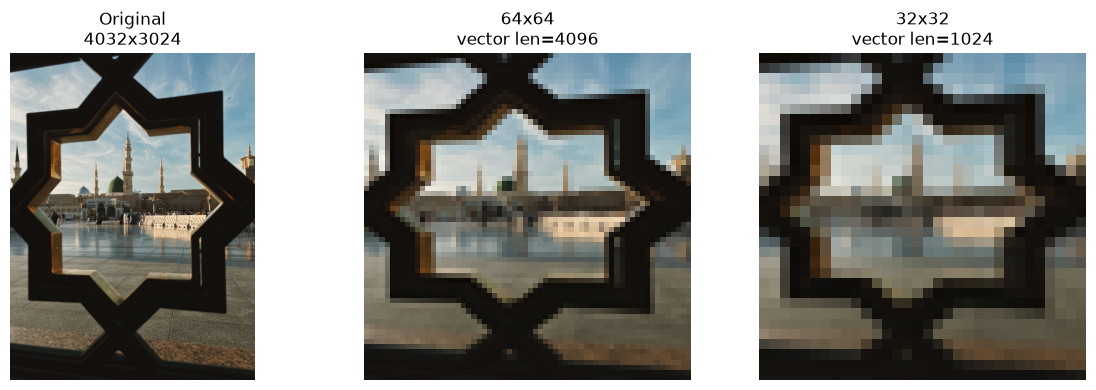

64x64 flattened length: 4096
32x32 flattened length: 1024


In [15]:
# Exercise 3: Resize comparison
img_64 = original_image.resize((64, 64))
img_32 = original_image.resize((32, 32))

vec_64 = np.array(img_64.convert('L')).flatten()
vec_32 = np.array(img_32.convert('L')).flatten()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(original_image); axes[0].set_title(f"Original\n{h}x{w}"); axes[0].axis('off')
axes[1].imshow(img_64); axes[1].set_title(f"64x64\nvector len={vec_64.size}"); axes[1].axis('off')
axes[2].imshow(img_32); axes[2].set_title(f"32x32\nvector len={vec_32.size}"); axes[2].axis('off')
plt.tight_layout()
plt.show()

print(f"64x64 flattened length: {vec_64.size}")
print(f"32x32 flattened length: {vec_32.size}")

In [16]:
# Exercise 4: Reusable function
def image_to_features(path, size=(64, 64)):
    """
    Load an image, resize to `size`, convert to grayscale, and flatten.
    Returns a 1D numpy array of length size[0]*size[1].
    """
    img = Image.open(path).convert('RGB')
    img = img.resize(size)
    gray = img.convert('L')
    return np.array(gray).flatten()

# Verify same output length for differently sized inputs
# (using dummy images here since we may not have 3 real files on disk)
dummy_paths = []
for i, dims in enumerate([(50, 80), (200, 150), (400, 400)]):
    dummy = np.random.randint(0, 256, size=(dims[1], dims[0], 3), dtype=np.uint8)
    p = f"dummy_{i}.png"
    Image.fromarray(dummy, 'RGB').save(p)
    dummy_paths.append(p)

for p in dummy_paths:
    vec = image_to_features(p, size=(64, 64))
    print(f"{p}: output shape = {vec.shape}")

dummy_0.png: output shape = (4096,)
dummy_1.png: output shape = (4096,)
dummy_2.png: output shape = (4096,)


In [17]:
# --- Home assignment scaffold --------------------------------------------
# Put your images in  data/class_a/  and  data/class_b/  then run this cell.

from glob import glob

CLASS_DIRS = {0: "data/class_a", 1: "data/class_b"}
SIZE = (64, 64)

X_list, y_list = [], []
for label, folder in CLASS_DIRS.items():
    paths = sorted(glob(os.path.join(folder, "*")))
    for p in paths:
        try:
            X_list.append(image_to_features(p, size=SIZE))
            y_list.append(label)
        except Exception as e:
            print(f"[SKIP] {p} -> {e}")

if X_list:
    X = np.vstack(X_list)
    y = np.array(y_list)
    np.savez("dataset.npz", X=X, y=y)

    print(f"X shape: {X.shape}   y shape: {y.shape}")
    print(f"Samples: {X.shape[0]}   Features per sample: {X.shape[1]}")
    print(f"Samples per feature: {X.shape[0] / X.shape[1]:.4f}")
    print()
    print("Saved dataset.npz")
else:
    print("No images found. Create data/class_a and data/class_b and add images.")

No images found. Create data/class_a and data/class_b and add images.
